<a href="https://colab.research.google.com/github/kareenadwight/ml_long_hm1/blob/main/Final_MAT3373_Long_HW1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 1(a)

$$
\text{Train}=\frac{1}{n}\sum_{i=1}^{n}(Y_i-\bar{Y})^2
$$

$$
\sum_{i=1}^{n}(Y_i-\bar{Y})^2
=\sum_{i=1}^{n}(Y_i-\mu)^2-n(\bar{Y}-\mu)^2
$$

$$
E[\text{Train}]
=\frac{1}{n}\left(n\sigma^2-n\frac{\sigma^2}{n}\right)
$$

$$
=\frac{n\sigma^2-\sigma^2}{n}
$$

$$
\boxed{E[\text{Train}]=\frac{n-1}{n}\sigma^2}
$$

### 1(b)

$$
\text{New}=(Y_{\text{new}}-\bar{Y})^2
$$

$$
E[Y_{\text{new}}-\bar{Y}]=\mu-\mu=0
$$

$$
E[\text{New}]=\operatorname{Var}(Y_{\text{new}}-\bar{Y})
$$

$$
=\operatorname{Var}(Y_{\text{new}})+\operatorname{Var}(\bar{Y})
$$

$$
=\sigma^2+\frac{\sigma^2}{n}
$$

$$
\boxed{E[\text{New}]=\left(1+\frac{1}{n}\right)\sigma^2}
$$

### 1(c)

The training error is usually smaller because the sample mean is calculated from the same data we use to measure the error. The mean is the value that gives the smallest squared error for those specific observations. A new observation was not used to calculate the mean, so the mean may not be as close to it. This makes the expected error on new data higher, even when the predictor is just a constant.

### 1(d)

$$
n=10,\quad \mu=0,\quad \sigma=1
$$

$$
E[\text{Train}]=\frac{10-1}{10}(1)^2=0.9
$$

$$
E[\text{New}]=\left(1+\frac{1}{10}\right)(1)^2=1.1
$$

In [ ]:
import numpy as np

np.random.seed(3373)

train = []
new = []

for i in range(20000):
    y = np.random.normal(0, 1, 10)
    avg = np.mean(y)

    train.append(np.mean((y - avg)**2))

    y_new = np.random.normal(0, 1)
    new.append((y_new - avg)**2)

print("Training:", np.mean(train))
print("New data:", np.mean(new))

print("Expected training:", 9/10)
print("Expected new data:", 11/10)

Training: 0.9036837750532355
New data: 1.0963582112925017
Expected training: 0.9
Expected new data: 1.1


###2(a)

Standardization is happening seperately with each fold.

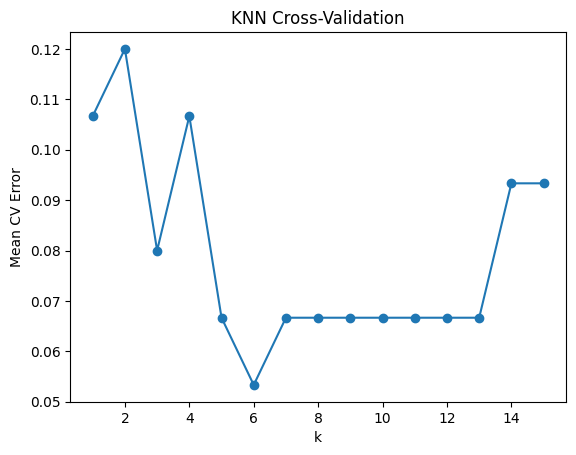

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.linear_model import LogisticRegression

data = pd.read_csv("iris.csv")

X = data.iloc[:, :4]
y = data.iloc[:, 4]

X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.5, random_state=3373, stratify=y
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=3373)

errors = []

for k in range(1, 16):
    model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    scores = cross_val_score(model, X_dev, y_dev, cv=cv)
    errors.append(1 - scores.mean())

plt.plot(range(1, 16), errors, marker="o")
plt.xlabel("k")
plt.ylabel("Mean CV Error")
plt.title("KNN Cross-Validation")
plt.show()

###2(b)

Here we are training KNN on the best k.

In [ ]:

best_k = np.argmin(errors) + 1

knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=best_k))
knn.fit(X_dev, y_dev)

knn_pred = knn.predict(X_test)

print("Best k:", best_k)
print("Test error:", 1 - accuracy_score(y_test, knn_pred))
print("Confusion matrix:")
print(confusion_matrix(y_test, knn_pred))

Best k: 6
Test error: 0.06666666666666665
Confusion matrix:
[[25  0  0]
 [ 0 24  1]
 [ 0  4 21]]


###2(c)

In [ ]:

log_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
log_model.fit(X_dev, y_dev)

log_pred = log_model.predict(X_test)

print("Test error:", 1 - accuracy_score(y_test, log_pred))
print("Confusion matrix:")
print(confusion_matrix(y_test, log_pred))


Test error: 0.06666666666666665
Confusion matrix:
[[25  0  0]
 [ 0 23  2]
 [ 0  3 22]]


###2(d)

The KNN and logistic regression had the same test error of 6.67%, so neither performed better overall. On a new independent test set, I would expect about the same error, with some small differences due to random variation.

###2(e)

Choosing k based on the lowest test error would give an overly optimistic result because we are using the test data to select the model. This could make the error look smaller than it would be on new data. Cross-validation avoids this problem by keeping the final test set separate.

###3(a)

The decision boundary is circular instead of linear.

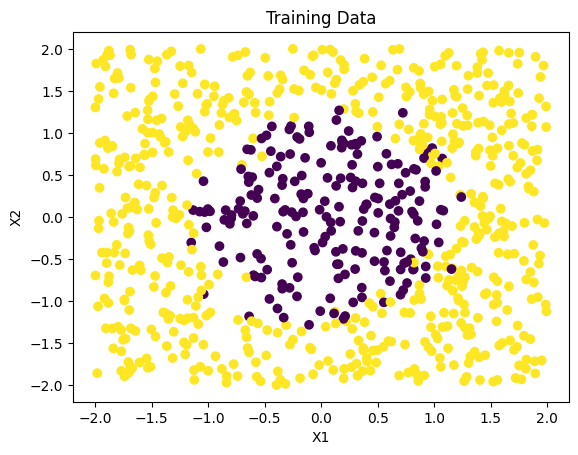

In [ ]:
train = pd.read_csv("circular_train.csv")

X = train.iloc[:, :2]
y = train.iloc[:, 2]

plt.scatter(X.iloc[:, 0], X.iloc[:, 1], c=y)
plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Training Data")
plt.show()

###3(b)

Ordinary logistic regression results in a straight-line boundary, which does not fit the circular pattern here well.

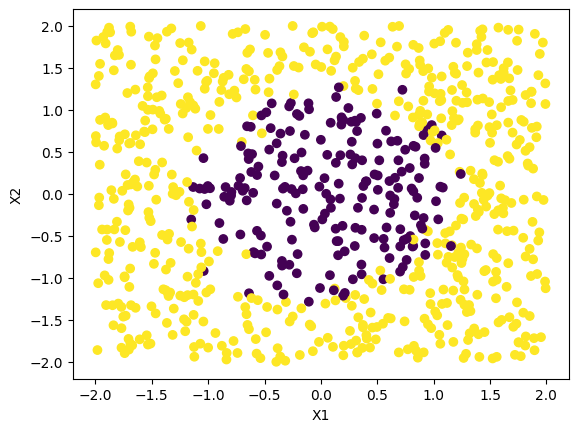

Boundary: 1.1065303935096664 + -0.01672141661970688 * X1 + 0.0003054133275067663 * X2 = 0


In [ ]:

model1 = LogisticRegression()
model1.fit(X, y)

a, b = model1.coef_[0]
c = model1.intercept_[0]

plt.scatter(X.iloc[:, 0], X.iloc[:, 1], c=y)

x1 = np.linspace(X.iloc[:, 0].min(), X.iloc[:, 0].max(), 200)

if abs(b) > 1e-10:
    x2 = -(a*x1 + c)/b
    plt.plot(x1, x2, color="red")
else:
    if abs(a) > 1e-10:
        plt.axvline(-c/a, color="red")

plt.xlabel("X1")
plt.ylabel("X2")
plt.xlim(-2.2, 2.2)
plt.ylim(-2.2, 2.2)
plt.show()

print("Boundary:", c, "+", a, "* X1 +", b, "* X2 = 0")



###3(c)

R² allows logistic regression to create a circular decision boundary, which better matches the pattern in the data as discussed.

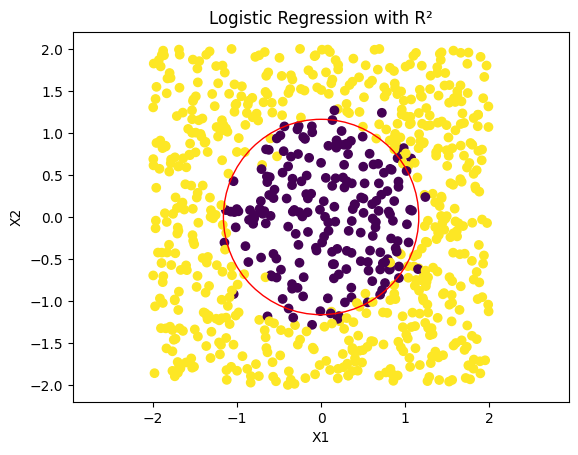

In [ ]:
r2 = X.iloc[:, 0]**2 + X.iloc[:, 1]**2

model2 = LogisticRegression()
model2.fit(r2.to_numpy().reshape(-1, 1), y)

radius2 = -model2.intercept_[0] / model2.coef_[0][0]

plt.scatter(X.iloc[:, 0], X.iloc[:, 1], c=y)

if radius2 > 0:
    circle = plt.Circle((0, 0), np.sqrt(radius2), fill=False, color="red")
    plt.gca().add_patch(circle)

plt.axis("equal")
plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Logistic Regression with R²")
plt.show()


###3(d)

In [ ]:

from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline

folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=3373)

neighbors = range(1, 42, 2)
cv_errors = []

for n in neighbors:
    classifier = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=n)
    )
    scores = cross_val_score(classifier, X, y, cv=folds)
    cv_errors.append(1 - scores.mean())

chosen_k = list(neighbors)[np.argmin(cv_errors)]

final_knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=chosen_k)
)
final_knn.fit(X, y)

print("Best k:", chosen_k)
print("CV error:", min(cv_errors))


Best k: 23
CV error: 0.04499999999999993


###3(e)

In [ ]:
from sklearn.metrics import zero_one_loss, log_loss

test = pd.read_csv("circular_test.csv")
y_test = test.iloc[:, 2]
X_test = test.iloc[:, :2]

r2_test = X_test.iloc[:, 0]**2 + X_test.iloc[:, 1]**2
r2_test = r2_test.to_numpy().reshape(-1, 1)

pred1 = model1.predict(X_test)
pred2 = model2.predict(r2_test)
pred3 = final_knn.predict(X_test)

print("Linear logistic error:", zero_one_loss(y_test, pred1))
print("R² logistic error:", zero_one_loss(y_test, pred2))
print("KNN error:", zero_one_loss(y_test, pred3))

print("Linear logistic log loss:", log_loss(y_test, model1.predict_proba(X_test)))
print("R² logistic log loss:", log_loss(y_test, model2.predict_proba(r2_test)))

Linear logistic error: 0.2676666666666667
R² logistic error: 0.05233333333333334
KNN error: 0.05566666666666664
Linear logistic log loss: 0.5821020118621717
R² logistic log loss: 0.12655681895427084


###3(e)

The model with the lowest test error performed best. A lower log loss also means the model made better probability predictions.

###3(f)

Adding R² lets logistic regression fit a circular boundary instead of a straight line. This shows that changing features can improve accuracy, but it does not mean it will always help.

###4(a)

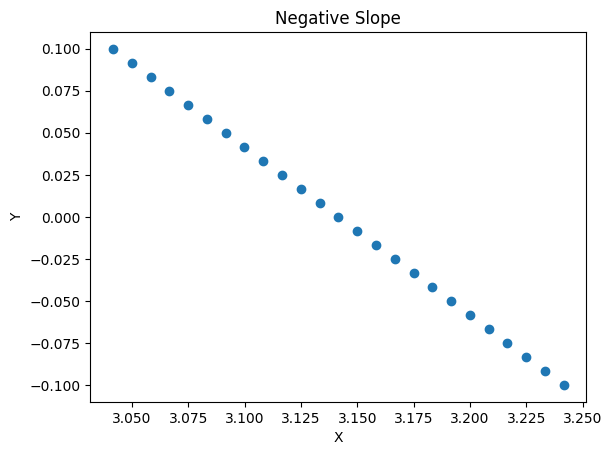

Slope: -0.9989193978642016
99% CI: [-0.99919356 -0.99864524]


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm

x = np.linspace(np.pi - 0.1, np.pi + 0.1, 25)
y = np.sin(x)

model = sm.OLS(y, sm.add_constant(x)).fit()

plt.scatter(x, y)
plt.xlabel("X")
plt.ylabel("Y")
plt.title("Negative Slope")
plt.show()

print("Slope:", model.params[1])
print("99% CI:", model.conf_int(alpha=0.01)[1])

###4(b)

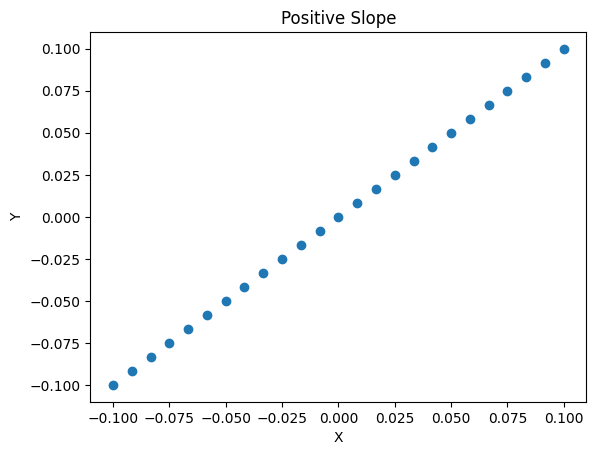

Slope: 0.9989193978642037
99% CI: [0.99864524 0.99919356]


In [ ]:
x = np.linspace(-0.1, 0.1, 25)
y = np.sin(x)

model = sm.OLS(y, sm.add_constant(x)).fit()

plt.scatter(x, y)
plt.xlabel("X")
plt.ylabel("Y")
plt.title("Positive Slope")
plt.show()

print("Slope:", model.params[1])
print("99% CI:", model.conf_int(alpha=0.01)[1])

###4(c)

Sin(X) cannot change faster than a slope of 1. This means the estimated slope cannot be above 100, so the confidence interval cannot be > 100 either.

###5(a)

In [ ]:
import numpy as np
import statsmodels.api as sm

rng = np.random.default_rng(3373)

X = rng.normal(size=(100, 80))
y = rng.normal(size=100)

corr = [np.corrcoef(X[:, i], y)[0, 1] for i in range(80)]
best = np.argsort(np.abs(corr))[-2:][::-1]

model = sm.OLS(y, sm.add_constant(X[:, best])).fit()

print("Selected predictors:", best)
print("Slopes:", model.params[1:])
print("95% CI:", model.conf_int()[1:])
print("P-values:", model.pvalues[1:])

Selected predictors: [77 12]
Slopes: [ 0.22919598 -0.23309156]
95% CI: [[ 0.05052979  0.40786218]
 [-0.41696252 -0.04922059]]
P-values: [0.01246988 0.0135107 ]


Both predictors appear significant even though there is no real relationship with y. This happens because we selected the strongest correlations from the same data.

###5(b)

Using separate data for selection and testing gives more reliable results.

In [ ]:
rng = np.random.default_rng(3373)

X = rng.normal(size=(100, 80))
y = rng.normal(size=100)

corr2 = [np.corrcoef(X[:50, i], y[:50])[0, 1] for i in range(80)]
best2 = np.argsort(np.abs(corr2))[-2:][::-1]

model2 = sm.OLS(
    y[50:],
    sm.add_constant(X[50:, best2])
).fit()

print("Selected predictors:", best2)
print("Slopes:", model2.params[1:])
print("95% CI:", model2.conf_int()[1:])
print("P-values:", model2.pvalues[1:])

Selected predictors: [12 46]
Slopes: [0.05679529 0.00655001]
95% CI: [[-0.17869433  0.29228491]
 [-0.21250066  0.22560068]]
P-values: [0.62979501 0.95228753]


###5(c)

In [ ]:
rng = np.random.default_rng(3373)

count1 = 0
count2 = 0

for i in range(200):
    X = rng.normal(size=(100, 80))
    y = rng.normal(size=100)

    corr = [np.corrcoef(X[:, j], y)[0, 1] for j in range(80)]
    best = np.argsort(np.abs(corr))[-2:]

    fit1 = sm.OLS(y, sm.add_constant(X[:, best])).fit()

    if np.any(fit1.pvalues[1:] < 0.05):
        count1 += 1

    corr2 = [np.corrcoef(X[:50, j], y[:50])[0, 1] for j in range(80)]
    best2 = np.argsort(np.abs(corr2))[-2:]

    fit2 = sm.OLS(y[50:], sm.add_constant(X[50:, best2])).fit()

    if np.any(fit2.pvalues[1:] < 0.05):
        count2 += 1

print("Same data:", count1 / 200)
print("Split data:", count2 / 200)

Same data: 0.93
Split data: 0.075


###5(d)

The first method finds more significant results because it uses the same data to choose and test predictors. The second method uses separate data, making the p-values more reliable. With two tests, the chance of getting at least one p-value below 0.05 is higher than 5%.

###6(a)

$$
\hat{f}_k(0)=\frac{1}{k}\sum_{i=1}^{k}Y_i
$$

$$
E[\hat{f}_k(0)]=\frac{1}{k}\sum_{i=1}^{k}\frac{i}{n}
$$

$$
=\frac{k+1}{2n}
$$

$$
\mathrm{Bias}=\frac{k+1}{2n}
$$

$$
\mathrm{Var}(\hat{f}_k(0))=\frac{1}{k^2}\sum_{i=1}^{k}\sigma^2
$$

$$
\mathrm{Var}(\hat{f}_k(0))=\frac{\sigma^2}{k}
$$

###6(b)


$$
\mathrm{MSE}(k)=\mathrm{Bias}^2+\mathrm{Variance}
$$

$$
=\left(\frac{k+1}{2n}\right)^2+\frac{\sigma^2}{k}
$$

$$
\mathrm{MSE}(k)=\frac{(k+1)^2}{4n^2}+\frac{\sigma^2}{k}
$$


###6(c)

$$
\mathrm{MSE}(k)\approx\frac{k^2}{4n^2}+\frac{\sigma^2}{k}
$$

$$
\frac{d}{dk}\mathrm{MSE}(k)=\frac{k}{2n^2}-\frac{\sigma^2}{k^2}
$$

$$
\frac{k}{2n^2}-\frac{\sigma^2}{k^2}=0
$$

$$
k^3=2n^2\sigma^2
$$

$$
k=(2n^2\sigma^2)^{1/3}
$$

$$
k\asymp n^{2/3}
$$

###6(d)

$$
n=200,\quad \sigma=0.2
$$

$$
\mathrm{MSE}(k)=\frac{(k+1)^2}{4(200)^2}+\frac{0.2^2}{k}
$$

$$
\mathrm{MSE}(1)=0.040025
$$

$$
\mathrm{MSE}(5)=0.008225
$$

$$
\mathrm{MSE}(15)\approx0.004267
$$

$$
\mathrm{MSE}(50)\approx0.017056
$$

###6(e)

The calculation works because the X values are fixed and the errors are independent with equal variance. More flexible methods may have higher variance, but not always the case.

###7(a)


In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score

df = pd.read_csv("repeated_visits.csv")

features = ["signal"] + [f"fingerprint_{i}" for i in range(1, 7)]

X7 = df[features]
y7 = df["outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X7, y7, test_size=0.5,
    random_state=3373, stratify=y7
)

log_model = make_pipeline(StandardScaler(), LogisticRegression())
knn_model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=1))

log_model.fit(X_train, y_train)
knn_model.fit(X_train, y_train)

print("Logistic accuracy:", accuracy_score(y_test, log_model.predict(X_test)))
print("1-NN accuracy:", accuracy_score(y_test, knn_model.predict(X_test)))


Logistic accuracy: 0.6504
1-NN accuracy: 0.8872


###7(b)

In [ ]:
from sklearn.model_selection import GroupShuffleSplit

split = GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=3373)

train_idx, test_idx = next(split.split(X7, y7, groups=df["person_id"]))

X_train2 = X7.iloc[train_idx]
X_test2 = X7.iloc[test_idx]
y_train2 = y7.iloc[train_idx]
y_test2 = y7.iloc[test_idx]

log_model.fit(X_train2, y_train2)
knn_model.fit(X_train2, y_train2)

print("Logistic accuracy:", accuracy_score(y_test2, log_model.predict(X_test2)))
print("1-NN accuracy:", accuracy_score(y_test2, knn_model.predict(X_test2)))

Logistic accuracy: 0.6648
1-NN accuracy: 0.5152


###7(c)

$$
P(\text{at least one})=1-\left(\frac{1}{2}\right)^4
$$

$$
=1-\frac{1}{16}=\frac{15}{16}=0.9375
$$

Probability = 93.75%

###7(d)

The row split tests how well the model predicts another visit from someone already in the dataset. The group split tests how well it predicts outcomes for new people.
###7(e)


The group split is more useful for predicting entirely new people because it tests on unseen individuals. Before using the model, I would also test it on a separate dataset of new people.

###7(f)

In [ ]:
X_small = df[["signal"]]

# Row split
Xa, Xb, ya, yb = train_test_split(
    X_small, y7, test_size=0.5,
    random_state=3373, stratify=y7
)

log_model.fit(Xa, ya)
knn_model.fit(Xa, ya)

print("Row split:")
print("Logistic:", accuracy_score(yb, log_model.predict(Xb)))
print("1-NN:", accuracy_score(yb, knn_model.predict(Xb)))

# Group split
train_idx, test_idx = next(
    split.split(X_small, y7, groups=df["person_id"])
)

Xa = X_small.iloc[train_idx]
Xb = X_small.iloc[test_idx]
ya = y7.iloc[train_idx]
yb = y7.iloc[test_idx]

log_model.fit(Xa, ya)
knn_model.fit(Xa, ya)

print("Group split:")
print("Logistic:", accuracy_score(yb, log_model.predict(Xb)))
print("1-NN:", accuracy_score(yb, knn_model.predict(Xb)))

Row split:
Logistic: 0.6376
1-NN: 0.5584
Group split:
Logistic: 0.656
1-NN: 0.572
